# 04 — Negative prices: how often, when, and is it increasing?

**Definition:** an interval is "negative" when **RRP ≤ $0** (the plan's threshold; $0 itself is included because
plenty of intervals clear at exactly zero when renewables are setting price). Strictly-below-zero counts are shown too.

**Method:** share of intervals at or below $0, by hour × month (heatmap), by month over time (trend) and by FY (table).
The sample runs Oct 2021 – Sep 2026, so every calendar month appears exactly 5 times and the heatmap is balanced.
The June 2022 suspension is excluded.

**What to look for:** midday spring clustering, and whether it's growing year on year.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sys.path.append("../src")
from chart_style import apply_style, save_chart, REGION_COLOR, SEQUENTIAL, SURFACE, INK_2, MUTED

apply_style()

df = pd.read_parquet("../data/clean/nem_5min.parquet")
df = df[~df["is_suspension"]].copy()

df["is_negative"] = df["RRP"] <= 0
df["is_below_zero"] = df["RRP"] < 0

PARTIAL_FY = {"FY22": "Oct–Jun only", "FY27": "Jul–Sep only"}

## 1. How often — by financial year

In [2]:
def negative_stats(g):
    neg = g.loc[g["is_negative"], "RRP"]
    return pd.Series({
        "share_le_0": g["is_negative"].mean(),
        "share_lt_0": g["is_below_zero"].mean(),
        "hours_le_0": g["is_negative"].sum() * 5 / 60,
        "median_price_when_le_0": neg.median(),
        "intervals_le_minus_100": (g["RRP"] <= -100).sum(),
    })


by_fy = df.groupby(["REGIONID", "fy"])[["RRP", "is_negative", "is_below_zero"]].apply(negative_stats)
by_fy["note"] = by_fy.index.get_level_values("fy").map(PARTIAL_FY).fillna("")
by_fy.style.format({
    "share_le_0": "{:.1%}", "share_lt_0": "{:.1%}", "hours_le_0": "{:,.0f}",
    "median_price_when_le_0": "{:,.2f}", "intervals_le_minus_100": "{:,.0f}",
})

- `share_le_0` — share of the FY's intervals at or below $0
- `hours_le_0` — the same as hours in the year (out of ~8,760)
- `median_price_when_le_0` — how negative it typically gets: near $0 means plants are just shutting off; well below means they are paying to keep running (subsidy, contracts, minimum-run constraints)

## 2. When — hour × month heatmap

Colour = share of intervals in that hour-of-day and calendar month that were at or below $0, pooled over all 5 years.
Both regions use the **same colour scale** so they can be compared directly.

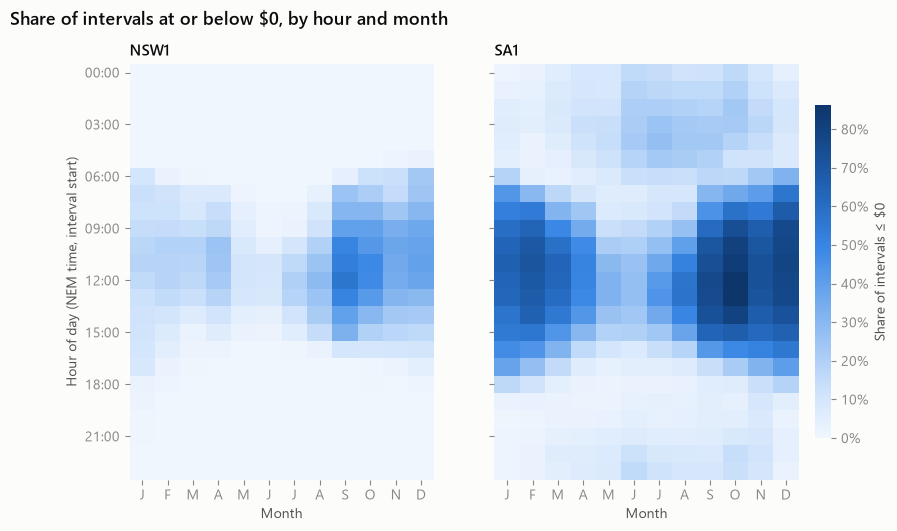

In [3]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

heat = df.groupby(["REGIONID", "hour", "month"])["is_negative"].mean()
vmax = heat.max()


def plot_heatmaps(heat, regions=("NSW1", "SA1"), title="Share of intervals at or below $0, by hour and month"):
    fig, axes = plt.subplots(1, len(regions), figsize=(5.2 * len(regions), 5.4), sharey=True, squeeze=False)
    for ax, region in zip(axes.flat, regions):
        grid = heat.loc[region].unstack("month").reindex(index=range(24), columns=range(1, 13))
        im = ax.imshow(grid, cmap=SEQUENTIAL, vmin=0, vmax=vmax, aspect="auto", origin="upper")
        ax.set_title(region)
        ax.set_xticks(range(12), [m[0] for m in MONTHS])
        ax.set_yticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
        ax.set_xlabel("Month")
        ax.grid(False)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[0, 0].set_ylabel("Hour of day (NEM time, interval start)")
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8, pad=0.02)
    cbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
    cbar.outline.set_visible(False)
    cbar.set_label("Share of intervals ≤ $0", color=INK_2)
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="semibold")
    return fig


fig = plot_heatmaps(heat)
save_chart(fig, "../charts/04_negative_heatmap.png")

**What it shows:** _your sentence_

**Why it matters to a trader:** _your sentence_

In [4]:
# The numbers behind the hottest cells
top_cells = heat.rename("share_le_0").reset_index().sort_values("share_le_0", ascending=False)
top_cells["month"] = top_cells["month"].map(dict(enumerate(MONTHS, start=1)))
top_cells.groupby("REGIONID").head(5).style.format({"share_le_0": "{:.0%}"}).hide(axis="index")

REGIONID,hour,month,share_le_0
SA1,13,Oct,86%
SA1,12,Oct,86%
SA1,11,Oct,82%
SA1,10,Oct,80%
SA1,14,Oct,80%
NSW1,12,Sep,56%
NSW1,11,Sep,53%
NSW1,13,Sep,51%
NSW1,10,Sep,50%
NSW1,11,Oct,49%


## 3. Is it increasing? — monthly trend

Share of each month's intervals at or below $0. Seasonality (spring peaks) sits on top of any trend, so compare
the same month across years rather than neighbouring months.

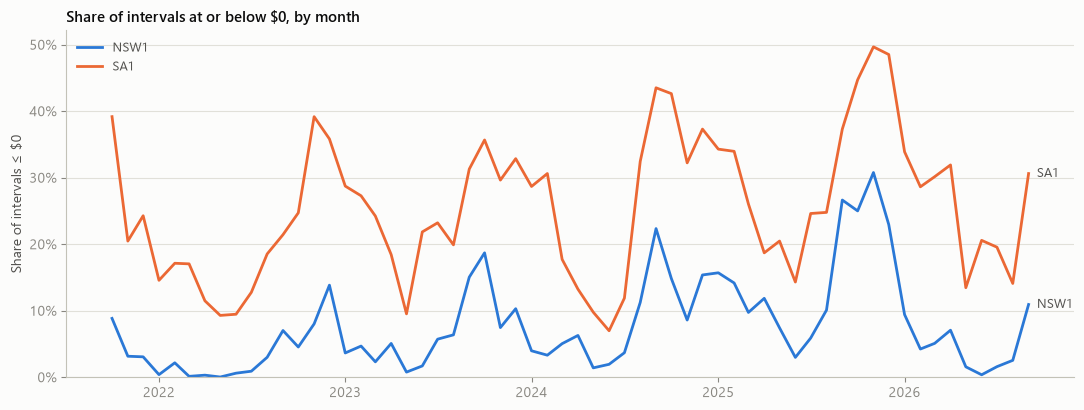

In [5]:
monthly = df.groupby(["REGIONID", df["interval_start"].dt.to_period("M")])["is_negative"].mean()

fig, ax = plt.subplots(figsize=(11, 4.2))
for region in ["NSW1", "SA1"]:
    s = monthly.loc[region]
    ax.plot(s.index.to_timestamp(), s.values, color=REGION_COLOR[region], lw=2, label=region)
    ax.annotate(region, (s.index[-1].to_timestamp(), s.values[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9.5, color=INK_2)

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, None)
ax.set_ylabel("Share of intervals ≤ $0")
ax.set_title("Share of intervals at or below $0, by month")
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, loc="upper left")
fig.tight_layout()
save_chart(fig, "../charts/04_negative_trend.png")

In [6]:
# Same month, different years: share of intervals <= $0 (rows = calendar year, columns = month)
same_month = monthly.rename("share").reset_index()
same_month["year"] = same_month["interval_start"].dt.year
same_month["month"] = same_month["interval_start"].dt.month.map(dict(enumerate(MONTHS, start=1)))
pivot = same_month.pivot_table(index=["REGIONID", "year"], columns="month", values="share")[MONTHS]
pivot.style.format("{:.0%}", na_rep="")

## 4. Spring midday, year by year

The cell the plan says to watch: Sep–Nov, 10:00–14:55. Is it getting more negative every year?
Partial springs: 2021 is Oct–Nov only, 2026 is Sep only (Sep is usually the least negative spring month).

In [7]:
spring_midday = df[df["season"].eq("spring") & df["hour"].between(10, 14)]
spring_year = spring_midday["interval_start"].dt.year.rename("year")
spring_midday.groupby(["REGIONID", spring_year])["is_negative"].mean().unstack("year").style.format("{:.0%}")

year,2021,2022,2023,2024,2025,2026
REGIONID,,,,,,
NSW1,21%,21%,43%,44%,74%,34%
SA1,68%,61%,79%,85%,88%,65%


## Try it yourself

- Change the threshold from `<= 0` to `< -50`: how much of the negative pricing is "deep" rather than near zero?
- Re-draw the heatmap for one FY only (filter `df` by `fy` before `heat`) and compare FY23 with FY26
- Split by `is_weekend`: are weekends more negative (lower demand, same solar)?